In [ ]:
#PRACTICAL:1
#Write a Python function to implement a McCulloch-Pitts neuron that performs the AND logical operation.Test the function with different input values.
def Mp_AND(x1,x2):
  w1 = w2= 1
  threshold = 2
  if x1 * w1 + x2 * w2 >= threshold:
    return 1
  return 0

for x1, x2 in [(0,0) ,(0,1), (1,2), (1,1)]:
  print(x1 ,x2, '->',Mp_AND(x1,x2))



0 0 -> 0
0 1 -> 0
1 2 -> 1
1 1 -> 1


In [ ]:
#PRACTICAL:2
#Implement a simple MLP in Python using NumPy to classify handwritten digits from theM NIST dataset.Describe the architecture,including the number of layers and neurons per layer.
import numpy as np
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

mnist = fetch_openml('mnist_784', version=1, as_frame=False)

X = mnist.data.astype(np.float32)
y = mnist.target.astype(int)

X = X / 255.0

X = X[:10000]
y = y[:10000]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


def one_hot(y, classes=10):
    result = np.zeros((len(y), classes))
    result[np.arange(len(y)), y] = 1
    return result

y_train = one_hot(y_train)


def relu(x):
    return np.maximum(0, x)

def relu_derivative(x):
    return (x > 0).astype(float)

def softmax(x):
    exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)

input_neurons = 784
hidden_neurons = 128
output_neurons = 10
np.random.seed(42)
W1 = np.random.randn(input_neurons, hidden_neurons) * 0.01
b1 = np.zeros((1, hidden_neurons))
W2 = np.random.randn(hidden_neurons, output_neurons) * 0.01
b2 = np.zeros((1, output_neurons))
learning_rate = 0.1
epochs = 10
batch_size = 64
for epoch in range(epochs):

    indices = np.random.permutation(len(X_train))
    X_train = X_train[indices]
    y_train = y_train[indices]

    for i in range(0, len(X_train), batch_size):

        X_batch = X_train[i:i + batch_size]
        y_batch = y_train[i:i + batch_size]

        Z1 = np.dot(X_batch, W1) + b1
        A1 = relu(Z1)

        Z2 = np.dot(A1, W2) + b2
        A2 = softmax(Z2)
        m = X_batch.shape[0]
        dZ2 = A2 - y_batch
        dW2 = np.dot(A1.T, dZ2) / m
        db2 = np.sum(dZ2, axis=0, keepdims=True) / m

        dA1 = np.dot(dZ2, W2.T)
        dZ1 = dA1 * relu_derivative(Z1)
        dW1 = np.dot(X_batch.T, dZ1) / m
        db1 = np.sum(dZ1, axis=0, keepdims=True) / m

        W2 -= learning_rate * dW2
        b2 -= learning_rate * db2
        W1 -= learning_rate * dW1
        b1 -= learning_rate * db1

    print("Epoch", epoch + 1, "completed")


Z1 = np.dot(X_test, W1) + b1
A1 = relu(Z1)

Z2 = np.dot(A1, W2) + b2
A2 = softmax(Z2)

predictions = np.argmax(A2, axis=1)

accuracy = np.mean(predictions == y_test)

print("Test Accuracy:", accuracy)

Epoch 1 completed
Epoch 2 completed
Epoch 3 completed
Epoch 4 completed
Epoch 5 completed
Epoch 6 completed
Epoch 7 completed
Epoch 8 completed
Epoch 9 completed
Epoch 10 completed
Test Accuracy: 0.933


In [ ]:
#practical 3
#Implement a feedforward neuralnetwork using a sigmoid activation function for hiddenlayers and a softmax activation function for the outputlayer.Train it on the Iris dataset.
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

iris = load_iris()

X = iris.data
y = iris.target

scaler = StandardScaler()
X = scaler.fit_transform(X)

#Convert class labels into one-hot encoding
y_onehot = np.zeros((len(y), 3))
y_onehot[np.arange(len(y)), y] = 1


X_train, X_test, y_train, y_test = train_test_split(
    X, y_onehot,
    test_size=0.2,
    random_state=42,
    stratify=y
)

#Initialize weights and biases
np.random.seed(42)

input_neurons = 4
hidden_neurons = 8
output_neurons = 3

W1 = np.random.randn(input_neurons, hidden_neurons) * 0.1
b1 = np.zeros((1, hidden_neurons))

W2 = np.random.randn(hidden_neurons, output_neurons) * 0.1
b2 = np.zeros((1, output_neurons))

learning_rate = 0.1

#Activation functions

def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def softmax(x):
    exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)

#Training
for epoch in range(1000):

    #Forward propagation
    hidden_input = np.dot(X_train, W1) + b1
    hidden_output = sigmoid(hidden_input)

    output_input = np.dot(hidden_output, W2) + b2
    output = softmax(output_input)

    #Cross-entropy loss
    loss = -np.mean(
        np.sum(y_train * np.log(output + 1e-8), axis=1)
    )

    #Backpropagation

    #Output layer error
    output_error = output - y_train

    #Gradient for W2
    dW2 = np.dot(hidden_output.T, output_error) / len(X_train)

    #Gradient for b2
    db2 = np.mean(output_error, axis=0, keepdims=True)

    hidden_error = np.dot(output_error, W2.T)
    hidden_derivative = hidden_output * (1 - hidden_output)

    hidden_delta = hidden_error * hidden_derivative

    #Gradient for W1
    dW1 = np.dot(X_train.T, hidden_delta) / len(X_train)

    #Gradient for b1
    db1 = np.mean(hidden_delta, axis=0, keepdims=True)

    #Update weights

    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

    if epoch % 100 == 0:
        print("Epoch:", epoch, "Loss:", loss)

#Testing

hidden_output = sigmoid(np.dot(X_test, W1) + b1)

output = softmax(
    np.dot(hidden_output, W2) + b2
)

predictions = np.argmax(output, axis=1)

actual = np.argmax(y_test, axis=1)

accuracy = accuracy_score(actual, predictions)

print("\nTest Accuracy:", accuracy)

Epoch: 0 Loss: 1.104026520711993
Epoch: 100 Loss: 0.9098182603705426
Epoch: 200 Loss: 0.5466721174323673
Epoch: 300 Loss: 0.4192209363642683
Epoch: 400 Loss: 0.34632648864206256
Epoch: 500 Loss: 0.2934954323006374
Epoch: 600 Loss: 0.25260968231671793
Epoch: 700 Loss: 0.21967486602858832
Epoch: 800 Loss: 0.19272167337326498
Epoch: 900 Loss: 0.1707817922210643

Test Accuracy: 0.9666666666666667


In [ ]:
#practical 4
#Write a Python function to perform backpropagation on a single hidden layer neural network. Include weight updates using gradient descent.
import numpy as np
#XOR input and output

X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y = np.array([
    [0],
    [1],
    [1],
    [0]
])

def sigmoid(x):
    return 1 / (1 + np.exp(-x))


#Derivative of sigmoid
def sigmoid_derivative(x):
    return x * (1 - x)

np.random.seed(1)

W1 = np.random.randn(2, 2)
b1 = np.zeros((1, 2))

W2 = np.random.randn(2, 1)
b2 = np.zeros((1, 1))

learning_rate = 0.5

#Backpropagation training

for epoch in range(10000):

    #Forward propagation
    hidden_input = np.dot(X, W1) + b1
    hidden_output = sigmoid(hidden_input)

    final_input = np.dot(hidden_output, W2) + b2
    prediction = sigmoid(final_input)

    #Calculate error
    error = y - prediction

    #Backpropagation
    output_delta = error * sigmoid_derivative(prediction)
    hidden_error = np.dot(output_delta, W2.T)
    hidden_delta = hidden_error * sigmoid_derivative(hidden_output)

    #Update weights
    W2 += learning_rate * np.dot(
        hidden_output.T,
        output_delta
    )

    b2 += learning_rate * np.sum(
        output_delta,
        axis=0,
        keepdims=True
    )

    W1 += learning_rate * np.dot(
        X.T,
        hidden_delta
    )

    b1 += learning_rate * np.sum(
        hidden_delta,
        axis=0,
        keepdims=True
    )


    if epoch % 1000 == 0:
        mse = np.mean(error ** 2)
        print("Epoch:", epoch, "Error:", mse)

#Test
print("\nPredictions:")

for i in range(len(X)):

    hidden = sigmoid(np.dot(X[i:i+1], W1) + b1)

    result = sigmoid(np.dot(hidden, W2) + b2)

    print(
        X[i],
        "->",
        result[0][0],
        "->",
        round(result[0][0])
    )

Epoch: 0 Error: 0.256657767612402
Epoch: 1000 Error: 0.0814184234685893
Epoch: 2000 Error: 0.003449874864349259
Epoch: 3000 Error: 0.0015639952302803051
Epoch: 4000 Error: 0.0009946603172000007
Epoch: 5000 Error: 0.0007245986657864944
Epoch: 6000 Error: 0.0005680257893845743
Epoch: 7000 Error: 0.0004661951809847621
Epoch: 8000 Error: 0.00039482765744629016
Epoch: 9000 Error: 0.0003421098233023125

Predictions:
[0 0] -> 0.01546327217516621 -> 0
[0 1] -> 0.9836647402929448 -> 1
[1 0] -> 0.9833412375047107 -> 1
[1 1] -> 0.02056710469846725 -> 0


In [ ]:
#Practical 5
#Implement the RPROP (Resilient Propagation) algorithm for train in ganeural network. Test its performance on a simple classification problem.
import numpy as np

X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=float)

y = np.array([
    [0],
    [1],
    [1],
    [0]
], dtype=float)


def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def sigmoid_derivative(x):
    s = sigmoid(x)
    return s * (1 - s)

np.random.seed(42)


W1 = np.random.randn(2, 4) * 0.5
b1 = np.zeros((1, 4))

W2 = np.random.randn(4, 1) * 0.5
b2 = np.zeros((1, 1))


eta_plus = 1.2
eta_minus = 0.5

delta_max = 50.0
delta_min = 1e-6


delta_W1 = np.ones_like(W1) * 0.1
delta_b1 = np.ones_like(b1) * 0.1

delta_W2 = np.ones_like(W2) * 0.1
delta_b2 = np.ones_like(b2) * 0.1


prev_W1 = np.zeros_like(W1)
prev_b1 = np.zeros_like(b1)

prev_W2 = np.zeros_like(W2)
prev_b2 = np.zeros_like(b2)



epochs = 5000

for epoch in range(epochs):

    z1 = X @ W1 + b1
    a1 = sigmoid(z1)

    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)


    error = a2 - y
    loss = np.mean(error ** 2)


    d2 = error * sigmoid_derivative(z2)

    grad_W2 = a1.T @ d2
    grad_b2 = np.sum(d2, axis=0, keepdims=True)

    d1 = (d2 @ W2.T) * sigmoid_derivative(z1)

    grad_W1 = X.T @ d1
    grad_b1 = np.sum(d1, axis=0, keepdims=True)


    def rprop_update(weights, gradient, previous_gradient,
                      delta):

        product = gradient * previous_gradient


        same = product > 0
        delta[same] = np.minimum(
            delta[same] * eta_plus,
            delta_max
        )


        changed = product < 0
        delta[changed] = np.maximum(
            delta[changed] * eta_minus,
            delta_min
        )


        zero = product == 0


        weights[same | zero] -= (
            np.sign(gradient[same | zero]) *
            delta[same | zero]
        )



        return weights, gradient.copy(), delta


    W1, prev_W1, delta_W1 = rprop_update(
        W1, grad_W1, prev_W1, delta_W1
    )

    W2, prev_W2, delta_W2 = rprop_update(
        W2, grad_W2, prev_W2, delta_W2
    )


    b1, prev_b1, delta_b1 = rprop_update(
        b1, grad_b1, prev_b1, delta_b1
    )

    b2, prev_b2, delta_b2 = rprop_update(
        b2, grad_b2, prev_b2, delta_b2
    )


    if (epoch + 1) % 500 == 0:
        print(f"Epoch {epoch + 1}, Loss = {loss:.6f}")


z1 = X @ W1 + b1
a1 = sigmoid(z1)

z2 = a1 @ W2 + b2
predictions = sigmoid(z2)

classes = (predictions >= 0.5).astype(int)

accuracy = np.mean(classes == y) * 100

print("\nXOR Classification Results:")


for i in range(len(X)):
    print(
        f"Input: {X[i].astype(int)} "
        f"Target: {int(y[i][0])} "
        f"Prediction: {predictions[i][0]:.4f} "
        f"Class: {classes[i][0]}"
    )

print(f"\nAccuracy: {accuracy:.2f}%")

Epoch 500, Loss = 0.000000
Epoch 1000, Loss = 0.000000
Epoch 1500, Loss = 0.000000
Epoch 2000, Loss = 0.000000
Epoch 2500, Loss = 0.000000
Epoch 3000, Loss = 0.000000
Epoch 3500, Loss = 0.000000
Epoch 4000, Loss = 0.000000
Epoch 4500, Loss = 0.000000
Epoch 5000, Loss = 0.000000

XOR Classification Results:
Input: [0 0] Target: 0 Prediction: 0.0000 Class: 0
Input: [0 1] Target: 1 Prediction: 1.0000 Class: 1
Input: [1 0] Target: 1 Prediction: 1.0000 Class: 1
Input: [1 1] Target: 0 Prediction: 0.0000 Class: 0

Accuracy: 100.00%


MLP Test MSE: 0.009091412484352267
RBF Test MSE: 0.0018818542131922812


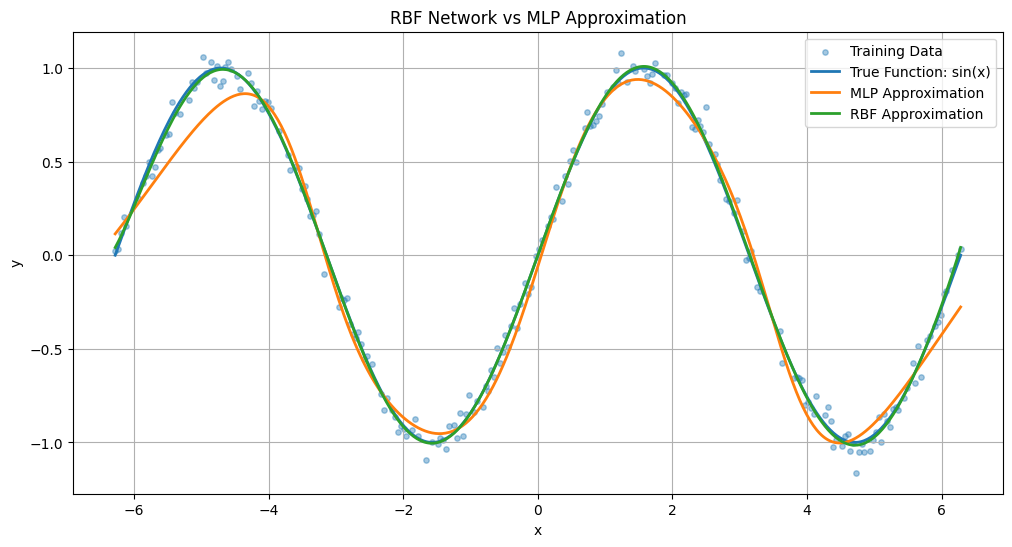


Performance comparision
RBF Test MSE : 0.001882
MLP Test MSE : 0.009091
RBF produced lower test error.


In [ ]:
#Practical 6
#Compare the approximation properties of a Radial Basis Function(RBF)network and a Multilayer Perceptron(MLP)by implementing both and training them on the same dataset.
import numpy as np
import matplotlib.pyplot as plt

from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

np.random.seed(42)

X = np.linspace(-2 * np.pi, 2 * np.pi, 300).reshape(-1, 1)
y = np.sin(X).ravel()

y_noisy = y + 0.05 * np.random.randn(len(y))

X_train, X_test, y_train, y_test = train_test_split(
    X, y_noisy, test_size=0.25, random_state=42
)

#Sort test data for smooth plotting
sort_idx = np.argsort(X_test[:, 0])
X_test = X_test[sort_idx]
y_test = y_test[sort_idx]

#MLP Network
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

mlp = MLPRegressor(
    hidden_layer_sizes=(20, 20),
    activation='tanh',
    solver='adam',
    learning_rate_init=0.01,
    max_iter=2000,
    random_state=42
)

mlp.fit(X_train_scaled, y_train)
mlp_pred = mlp.predict(X_test_scaled)
mlp_mse = mean_squared_error(y_test, mlp_pred)
print("MLP Test MSE:", mlp_mse)


#RBF Network
class RBFNetwork:
    def __init__(self, n_centers=20, sigma=None):
        self.n_centers = n_centers
        self.sigma = sigma
        self.centers = None
        self.weights = None

    def rbf(self, X):
#Calculate squared distance from every point to every center
        distances = np.sum(
            (X[:, np.newaxis, :] - self.centers[np.newaxis, :, :]) ** 2,
            axis=2
        )

        return np.exp(-distances / (2 * self.sigma ** 2))

    def fit(self, X, y):

#Select centers from training samples
        indices = np.linspace(
            0, len(X) - 1,
            self.n_centers
        ).astype(int)
        self.centers = X[indices]

#Calculate sigma automatically
        if self.sigma is None:
            center_distances = []

            for i in range(len(self.centers)):
                for j in range(i + 1, len(self.centers)):
                    d = np.linalg.norm(
                        self.centers[i] - self.centers[j]
                    )
                    center_distances.append(d)

            self.sigma = np.mean(center_distances)

#RBF hidden layer
        Phi = self.rbf(X)
#Add bias
        Phi = np.column_stack([Phi, np.ones(len(Phi))])
#Calculate output weights using least squares
        self.weights = np.linalg.pinv(Phi) @ y

    def predict(self, X):
        Phi = self.rbf(X)

#Add bias
        Phi = np.column_stack([Phi, np.ones(len(Phi))])
        return Phi @ self.weights
# Train RBF
rbf = RBFNetwork(n_centers=20)
rbf.fit(X_train, y_train)
rbf_pred = rbf.predict(X_test)
rbf_mse = mean_squared_error(y_test, rbf_pred)

print("RBF Test MSE:", rbf_mse)
#Approximation on Complete Dataset

X_plot = np.linspace(
    -2 * np.pi,
    2 * np.pi,
    500
).reshape(-1, 1)

true_y = np.sin(X_plot).ravel()

mlp_plot = mlp.predict(scaler.transform(X_plot))
rbf_plot = rbf.predict(X_plot)
#Plot Comparison
plt.figure(figsize=(12, 6))
plt.scatter(
    X_train,
    y_train,
    s=15,
    alpha=0.4,
    label="Training Data"
)
plt.plot(
    X_plot,
    true_y,
    linewidth=2,
    label="True Function: sin(x)"
)
plt.plot(
    X_plot,
    mlp_plot,
    linewidth=2,
    label="MLP Approximation"
)
plt.plot(
    X_plot,
    rbf_plot,
    linewidth=2,
    label="RBF Approximation"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("RBF Network vs MLP Approximation")
plt.legend()
plt.grid(True)
plt.show()
#Error Comparison
print("\nPerformance comparision")
print(f"RBF Test MSE : {rbf_mse:.6f}")
print(f"MLP Test MSE : {mlp_mse:.6f}")

if rbf_mse < mlp_mse:
    print("RBF produced lower test error.")
else:
    print("MLP produced lower test error.")


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1966s 12us/step
Training images: (50000, 32, 32, 3)
Testing images : (10000, 32, 32, 3)

Training CNN using: ReLU


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545,098 (2.08 MB)

 Trainable params: 545,098 (2.08 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 67s 93ms/step - accuracy: 0.4840 - loss: 1.4456 - val_accuracy: 0.5914 - val_loss: 1.1712
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 66s 94ms/step - accuracy: 0.6256 - loss: 1.0707 - val_accuracy: 0.6612 - val_loss: 0.9763
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 66s 94ms/step - accuracy: 0.6780 - loss: 0.9255 - val_accuracy: 0.6910 - val_loss: 0.9040
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 82s 95ms/step - accuracy: 0.7134 - loss: 0.8277 - val_accuracy: 0.7024 - val_loss: 0.8714
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 66s 94ms/step - accuracy: 0.7412 - loss: 0.7494 - val_accuracy: 0.7106 - val_loss: 0.8705
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 67s 94ms/step - accuracy: 0.7654 - loss: 0.6774 - val_accuracy: 0.7108 - val_loss: 0.8877
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 66s 93ms/step - accuracy: 0.7878 - loss: 0.6148 - val_accuracy: 0.6988 - val_loss: 0.9127
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 65s 92ms/step - accuracy: 0.8082 - loss: 0.5554 - 

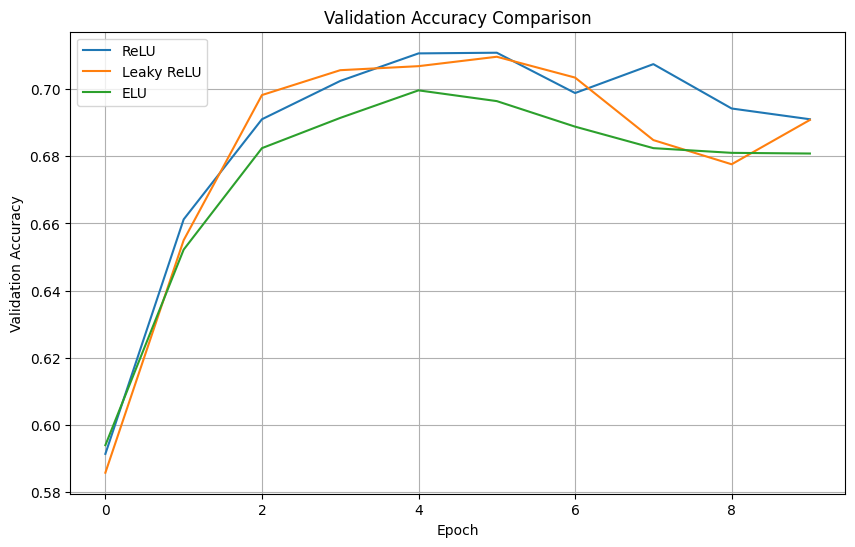

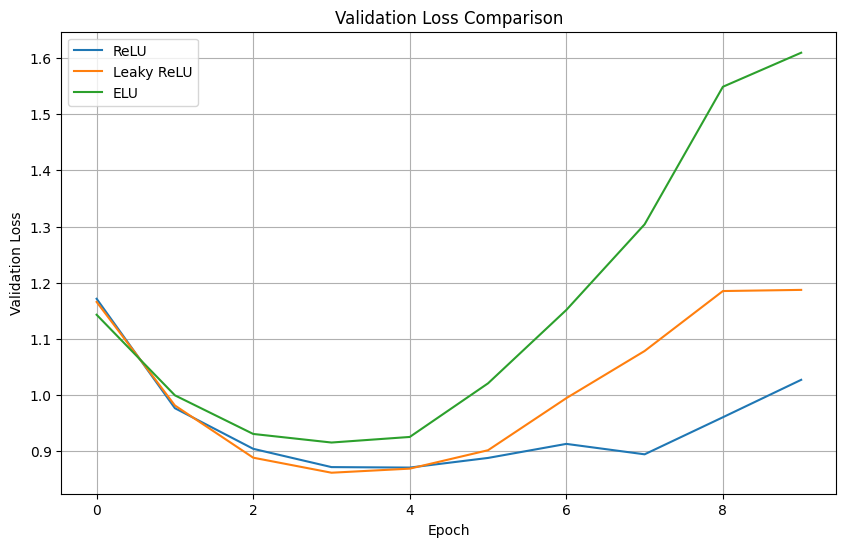

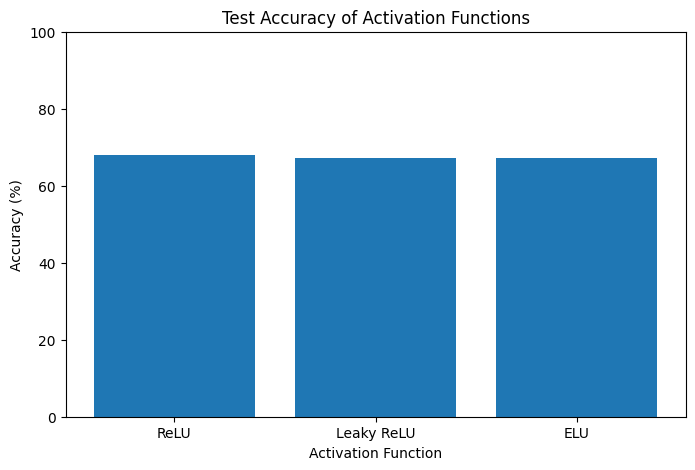

In [ ]:
#Practical 7
#Write Python code to implement different activation functions(ReLU,LeakyReLU,ELU).Compare their performance on the CIFAR-10 dataset using a simple CNN.

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time

from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical

(x_train, y_train), (x_test, y_test) = cifar10.load_data()

print("Training images:", x_train.shape)
print("Testing images :", x_test.shape)

#normalize
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)
def relu_activation():
    return layers.ReLU()

def leaky_relu_activation():
    return layers.LeakyReLU(negative_slope=0.01)
def elu_activation():
    return layers.ELU(alpha=1.0)
#create CNN model
def create_model(activation_name):
    model = models.Sequential()

#first convolution block
    model.add(
        layers.Conv2D(
            32,
            (3, 3),
            padding="same",
            input_shape=(32, 32, 3)
        )
    )

    if activation_name == "ReLU":
        model.add(relu_activation())

    elif activation_name == "Leaky ReLU":
        model.add(leaky_relu_activation())

    elif activation_name == "ELU":
        model.add(elu_activation())

    model.add(layers.MaxPooling2D((2, 2)))

#second convolution block
    model.add(
        layers.Conv2D(
            64,
            (3, 3),
            padding="same"
        )
    )

    if activation_name == "ReLU":
        model.add(relu_activation())

    elif activation_name == "Leaky ReLU":
        model.add(leaky_relu_activation())

    elif activation_name == "ELU":
        model.add(elu_activation())

    model.add(layers.MaxPooling2D((2, 2)))

#fully connected layers
    model.add(layers.Flatten())

    model.add(layers.Dense(128))

    if activation_name == "ReLU":
        model.add(relu_activation())
    elif activation_name == "Leaky ReLU":
        model.add(leaky_relu_activation())

    elif activation_name == "ELU":
        model.add(elu_activation())

    model.add(layers.Dense(10, activation="softmax"))

    model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

activation_functions = [
    "ReLU",
    "Leaky ReLU",
    "ELU"
]
results = {}
histories = {}


for activation in activation_functions:

    print("\n" + "=" * 60)
    print("Training CNN using:", activation)
    print("=" * 60)
    model = create_model(activation)

    if activation == "ReLU":
        model.summary()

    start_time = time.time()
    history = model.fit(
        x_train,
        y_train,
        epochs=10,
        batch_size=64,
        validation_split=0.1,
        verbose=1
    )

    training_time = time.time() - start_time

    test_loss, test_accuracy = model.evaluate(
        x_test,
        y_test,
        verbose=0
    )

    results[activation] = {
        "Test Accuracy": test_accuracy,
        "Test Loss": test_loss,
        "Training Time": training_time
    }

    histories[activation] = history

    print("\nResults for", activation)
    print("Test Accuracy :", round(test_accuracy * 100, 2), "%")
    print("Test Loss     :", round(test_loss, 4))
    print("Training Time :", round(training_time, 2), "seconds")

#Comp table
print("\n\nFINAL COMPARISON")
print("=" * 70)
print(
    f"{'Activation':<15}"
    f"{'Accuracy (%)':<18}"
    f"{'Loss':<15}"
    f"{'Time (sec)':<15}"
)

print("-" * 70)

for activation, result in results.items():

    print(
        f"{activation:<15}"
        f"{result['Test Accuracy'] * 100:<18.2f}"
        f"{result['Test Loss']:<15.4f}"
        f"{result['Training Time']:<15.2f}"
    )

#plot val accuracy
plt.figure(figsize=(10, 6))

for activation in activation_functions:

    plt.plot(
        histories[activation].history["val_accuracy"],
        label=activation
    )

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

#plot val Loss
plt.figure(figsize=(10, 6))

for activation in activation_functions:

    plt.plot(
        histories[activation].history["val_loss"],
        label=activation
    )

plt.title("Validation Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid()
plt.show()

#accuracy plot
names = list(results.keys())

accuracies = [
    results[name]["Test Accuracy"] * 100
    for name in names
]

plt.figure(figsize=(8, 5))

plt.bar(names, accuracies)

plt.title("Test Accuracy of Activation Functions")
plt.xlabel("Activation Function")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.show()


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.6428 - loss: 1.3519 - val_accuracy: 0.8388 - val_loss: 0.6076
Epoch 2/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.8700 - loss: 0.4851 - val_accuracy: 0.8908 - val_loss: 0.3881
Epoch 3/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8977 - loss: 0.3637 - val_accuracy: 0.9126 - val_loss: 0.3204
Epoch 4/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9106 - loss: 0.3138 - val_accuracy: 0.9198 - val_loss: 0.2840
Epoch 5/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9193 - loss: 0.2830 - val_accuracy: 0.9278 - val_loss: 0.2589
Epoch 6/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9257 - loss: 0.2600 - val_accuracy: 0.9330 - val_loss: 0.2397
Epoch 7/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9308 - loss: 0.2415 - val_accuracy: 0.9364 - val_loss: 0.2240
Epoch 8/10
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step

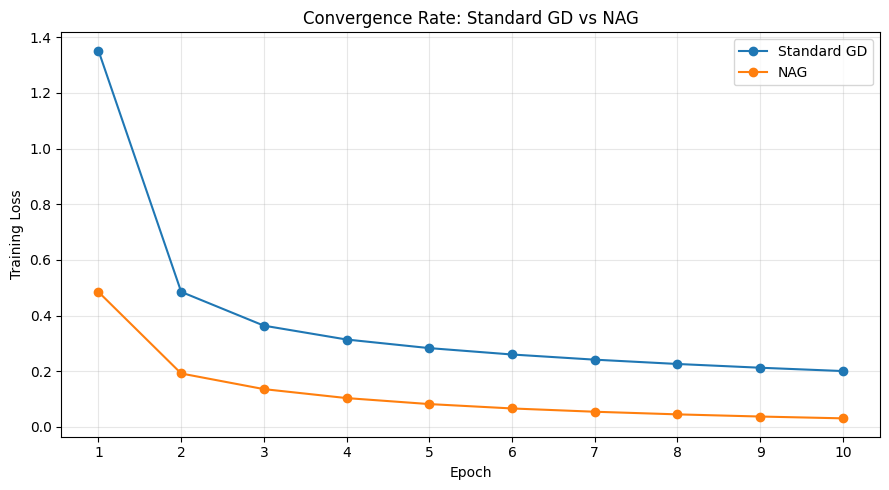

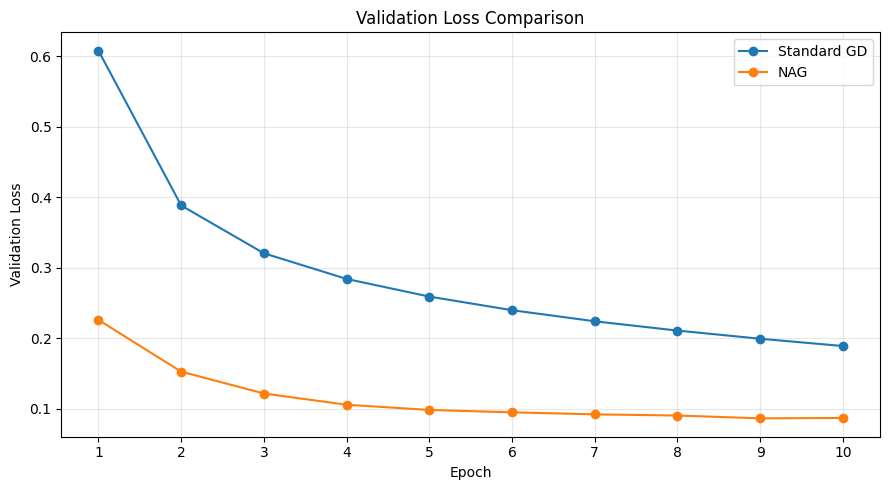

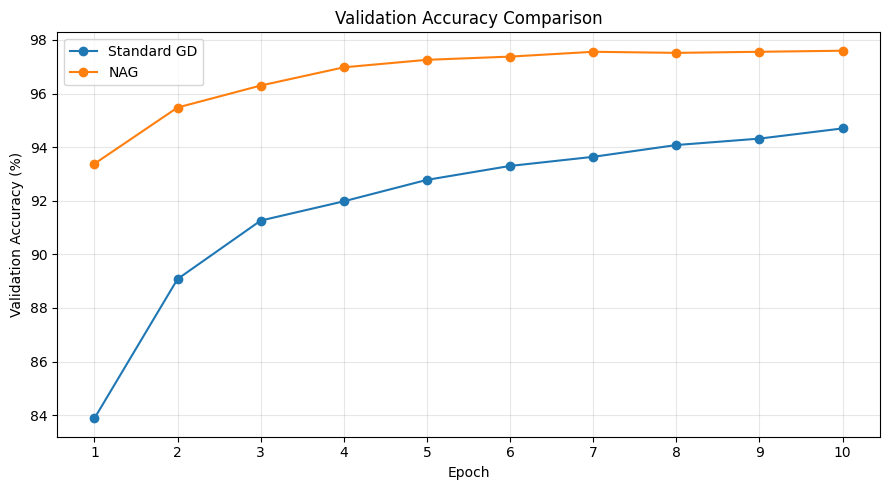


Epochs required to reach 95% validation accuracy:
Standard GD: Not reached
NAG: 2


In [ ]:
#Pracrical 8
#Implement the Nesterov Accelerated Gradient (NAG) optimization algorithm and compare its convergence rate with standard gradient descent on a deep neural network.

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import time
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

np.random.seed(42)
tf.keras.utils.set_random_seed(42)

(x_train, y_train), (x_test, y_test) = mnist.load_data()

#Normalize
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

#Flatten
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

x_val, y_val = x_train[:5000], y_train[:5000]
x_tr, y_tr = x_train[5000:], y_train[5000:]


def build_model():
    return Sequential([
        Input(shape=(784,)),
        Dense(256, activation="relu"),
        Dense(128, activation="relu"),
        Dense(64, activation="relu"),
        Dense(10, activation="softmax")
    ])

tf.keras.utils.set_random_seed(42)
initial_model = build_model()
initial_weights = initial_model.get_weights()

EPOCHS = 10
BATCH_SIZE = 128
LEARNING_RATE = 0.01
MOMENTUM = 0.9

histories = {}
models = {}
times = {}

#SDG
model_gd = build_model()
model_gd.set_weights(initial_weights)

model_gd.compile(
    optimizer=tf.keras.optimizers.SGD(
        learning_rate=LEARNING_RATE,
        momentum=0.0
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

start = time.time()

history_gd = model_gd.fit(
    x_tr, y_tr,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=False,
    verbose=1
)

times["Standard GD"] = time.time() - start
histories["Standard GD"] = history_gd.history
models["Standard GD"] = model_gd

#NAG
model_nag = build_model()
model_nag.set_weights(initial_weights)

model_nag.compile(
    optimizer=tf.keras.optimizers.SGD(
        learning_rate=LEARNING_RATE,
        momentum=MOMENTUM,
        nesterov=True
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

start = time.time()

history_nag = model_nag.fit(
    x_tr, y_tr,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=False,
    verbose=1
)

times["NAG"] = time.time() - start
histories["NAG"] = history_nag.history
models["NAG"] = model_nag

#Evaluate on the test dataset
print("\nFINAL PERFORMANCE COMPARISON")
print("-" * 72)
print(f"{'Metric':<25}{'Standard GD':>18}{'NAG':>18}")
print("-" * 72)

test_results = {}

for name, model in models.items():
    loss, accuracy = model.evaluate(x_test, y_test, verbose=0)
    test_results[name] = (loss, accuracy)

print(f"{'Test loss':<25}{test_results['Standard GD'][0]:>18.4f}"
      f"{test_results['NAG'][0]:>18.4f}")
print(f"{'Test accuracy (%)':<25}{test_results['Standard GD'][1]*100:>17.2f}"
      f"{test_results['NAG'][1]*100:>17.2f}")
print(f"{'Training time (sec)':<25}{times['Standard GD']:>18.2f}"
      f"{times['NAG']:>18.2f}")

epochs = range(1, EPOCHS + 1)

plt.figure(figsize=(9, 5))
for name in histories:
    plt.plot(epochs, histories[name]["loss"],
             marker="o", label=name)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Convergence Rate: Standard GD vs NAG")
plt.xticks(list(epochs))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
for name in histories:
    plt.plot(epochs, histories[name]["val_loss"],
             marker="o", label=name)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss Comparison")
plt.xticks(list(epochs))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
for name in histories:
    plt.plot(epochs, np.array(histories[name]["val_accuracy"]) * 100,
             marker="o", label=name)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("Validation Accuracy Comparison")
plt.xticks(list(epochs))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

target = 0.95

print(f"\nEpochs required to reach {target*100:.0f}% validation accuracy:")
for name, history in histories.items():
    reached = next(
        (i + 1 for i, acc in enumerate(history["val_accuracy"])
         if acc >= target),
        None
    )
    print(f"{name}: {reached if reached is not None else 'Not reached'}")


Loading MNIST dataset...
Dataset shape: (10000, 784)
Explained variance ratio:
First Principal Component (PC1): 0.10200026888748723
Second Principal Component (PC2): 0.07215439513825811
Total variance explained: 0.17415466402574534


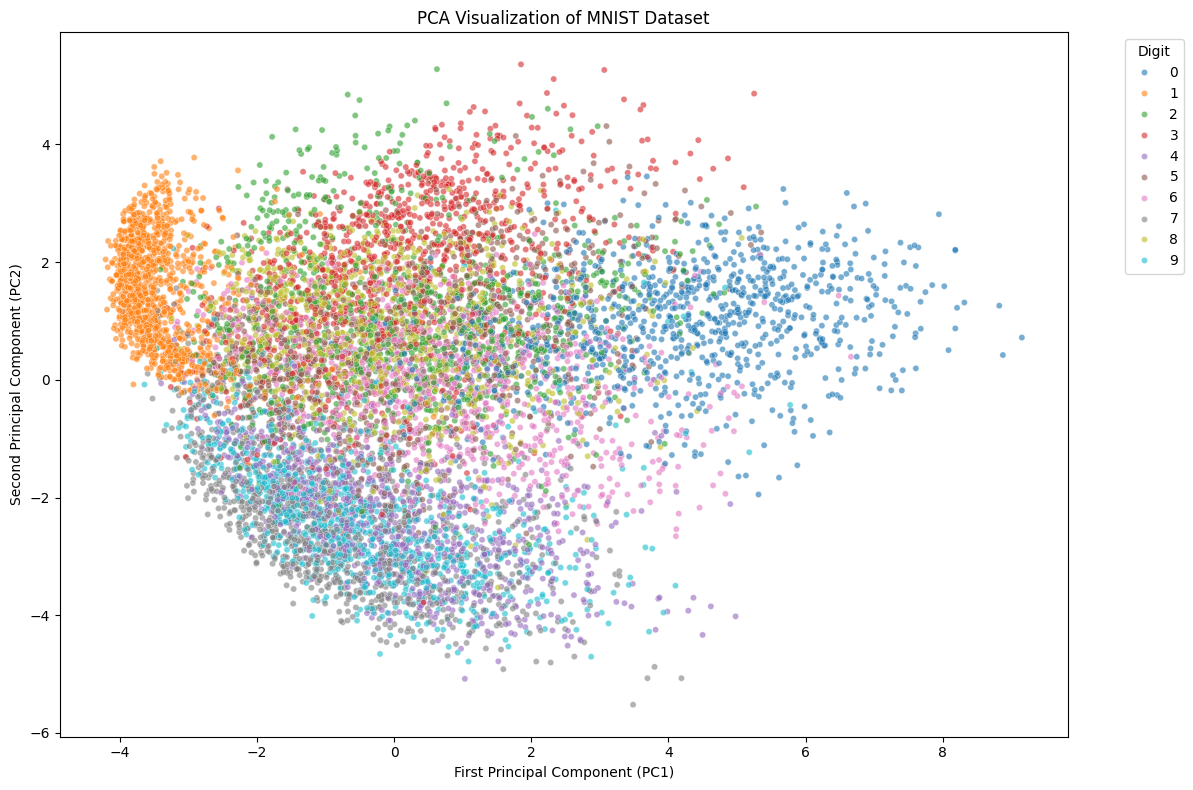

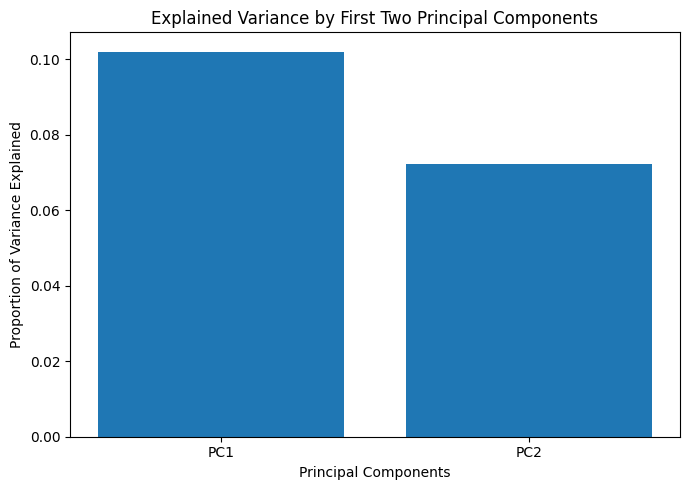

In [ ]:
#practical 9
#Perform Principal Component Analysis (PCA) on the MNIST dataset and interpret the first two principal components.Plot the results.
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

print("Loading MNIST dataset...")

mnist = fetch_openml('mnist_784', version=1, as_frame=False)
X = mnist.data
y = mnist.target.astype(int)

X = X[:10000]
y = y[:10000]

X = X / 255.0

print("Dataset shape:", X.shape)

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

print("Explained variance ratio:")
print("First Principal Component (PC1):",
      pca.explained_variance_ratio_[0])

print("Second Principal Component (PC2):",
      pca.explained_variance_ratio_[1])

print("Total variance explained:",
      sum(pca.explained_variance_ratio_))

import pandas as pd

df = pd.DataFrame({
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1],
    'Digit': y
})

plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=df,
    x='PC1',
    y='PC2',
    hue='Digit',
    palette='tab10',
    alpha=0.6,
    s=20
)

plt.title('PCA Visualization of MNIST Dataset')
plt.xlabel('First Principal Component (PC1)')
plt.ylabel('Second Principal Component (PC2)')
plt.legend(title='Digit', bbox_to_anchor=(1.05, 1),
           loc='upper left')

plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))

plt.bar(
    ['PC1', 'PC2'],
    pca.explained_variance_ratio_
)

plt.title('Explained Variance by First Two Principal Components')
plt.ylabel('Proportion of Variance Explained')
plt.xlabel('Principal Components')

plt.tight_layout()
plt.show()


Loading MNIST dataset
Dataset shape: (10000, 784)

Explained Variance:
PC1: 0.102
PC2: 0.0722
Total: 0.1742


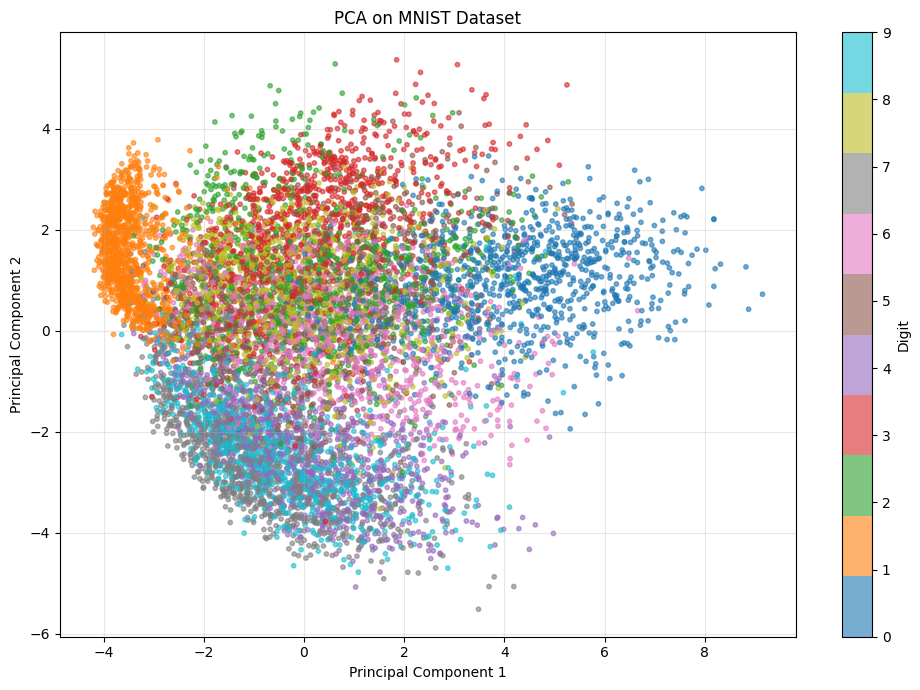

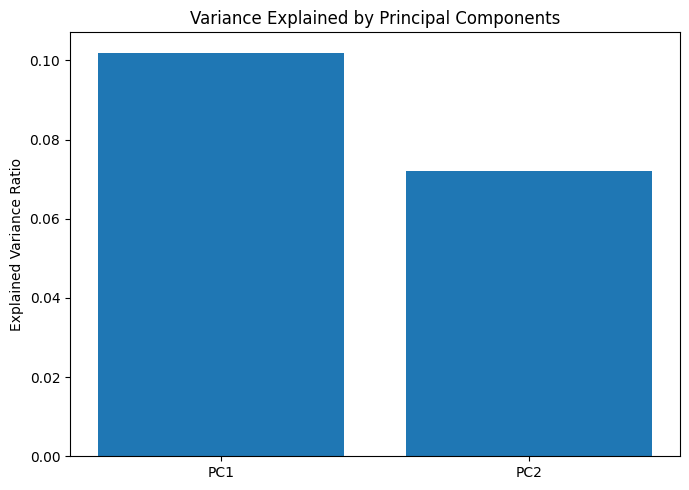

In [ ]:
#practical 9 second code
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

from tensorflow.keras.datasets import mnist

print("Loading MNIST dataset")

(X_train, y_train), (X_test, y_test) = mnist.load_data()

X = X_train[:10000]
y = y_train[:10000]

X = X.reshape(10000, 784)

X = X.astype(np.float32) / 255.0

print("Dataset shape:", X.shape)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

print("\nExplained Variance:")
print("PC1:", round(pca.explained_variance_ratio_[0], 4))
print("PC2:", round(pca.explained_variance_ratio_[1], 4))
print("Total:", round(pca.explained_variance_ratio_.sum(), 4))

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    cmap="tab10",
    s=10,
    alpha=0.6
)

plt.colorbar(scatter, label="Digit")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA on MNIST Dataset")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))

plt.bar(
    ["PC1", "PC2"],
    pca.explained_variance_ratio_
)

plt.ylabel("Explained Variance Ratio")
plt.title("Variance Explained by Principal Components")
plt.tight_layout()
plt.show()


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data: (60000, 28, 28)
Testing data: (10000, 28, 28)


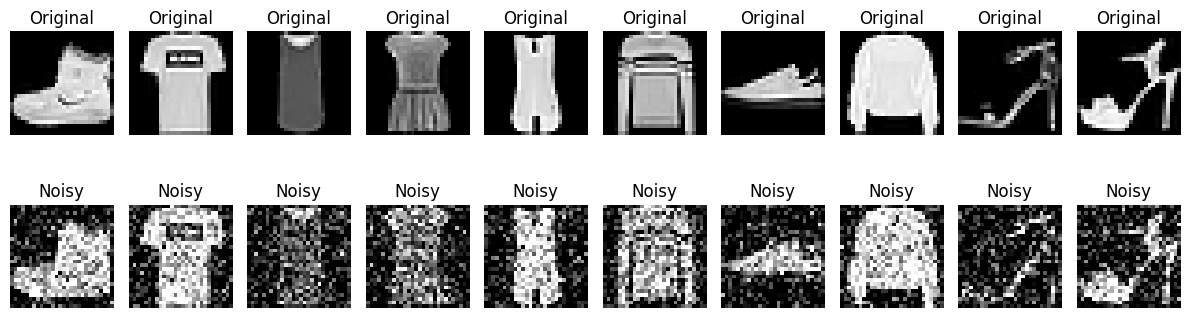

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 784)            │       101,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 28, 28)         │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 218,192 (852.31 KB)

 Trainable params: 218,192 (852.31 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 11s 37ms/step - loss: 0.3821 - val_loss: 0.3238
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step - loss: 0.3144 - val_loss: 0.3107
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - loss: 0.3052 - val_loss: 0.3045
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.3005 - val_loss: 0.3011
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 0.2974 - val_loss: 0.2983
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 0.2950 - val_loss: 0.2964
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.2932 - val_loss: 0.2948
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.2917 - val_loss: 0.2935
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.2906 - val_loss: 0.2925
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.2896 - val_loss: 0.2916
Test Reconstruction Loss: 0.29159289598464966
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


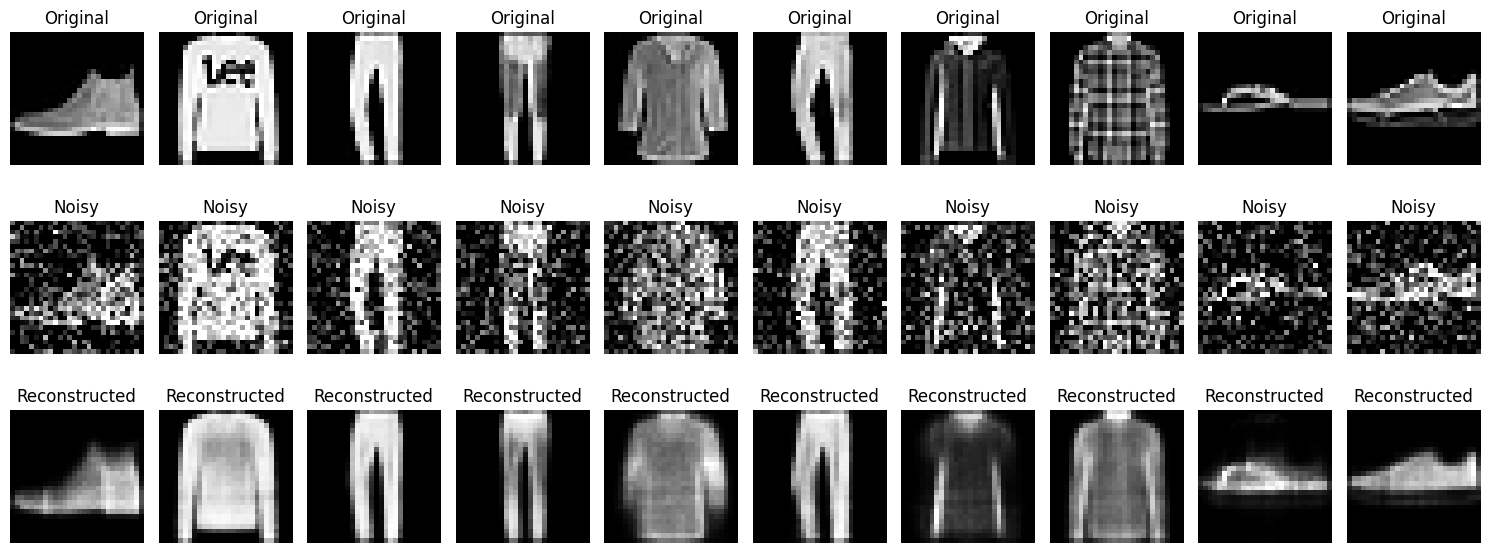

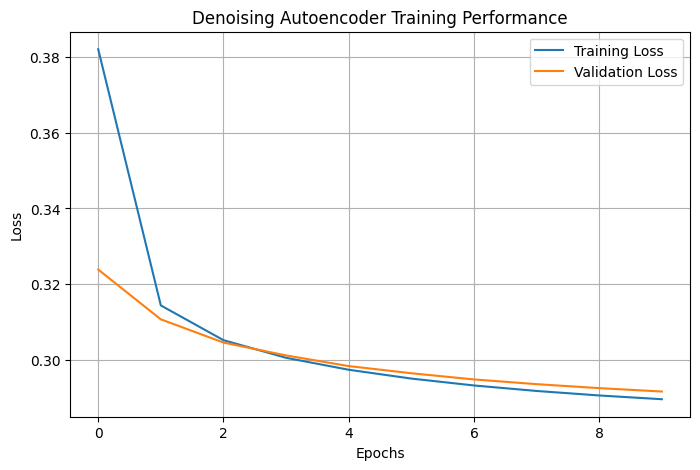

In [ ]:
#Practical 10
#Implement a denoising autoencoder and train it on the Fashion-MNIST dataset. Evaluate its performance by visualizing the original,noisy,and reconstructed images.
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Flatten, Reshape
from tensorflow.keras.optimizers import Adam

(x_train, _), (x_test, _) = fashion_mnist.load_data()
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)
noise_factor = 0.3
x_train_noisy = x_train + noise_factor * np.random.normal(
    loc=0.0, scale=1.0, size=x_train.shape
)

x_test_noisy = x_test + noise_factor * np.random.normal(
    loc=0.0, scale=1.0, size=x_test.shape
)

x_train_noisy = np.clip(x_train_noisy, 0., 1.)
x_test_noisy = np.clip(x_test_noisy, 0., 1.)

plt.figure(figsize=(12, 4))

for i in range(10):

    #Original images
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.axis('off')
    plt.title("Original")

    #Noisy images
    plt.subplot(2, 10, i + 11)
    plt.imshow(x_train_noisy[i], cmap='gray')
    plt.axis('off')
    plt.title("Noisy")

plt.tight_layout()
plt.show()
input_img = Input(shape=(28, 28))
#Encoder
x = Flatten()(input_img)
encoded = Dense(128, activation='relu')(x)
encoded = Dense(64, activation='relu')(encoded)

#Decoder
decoded = Dense(128, activation='relu')(encoded)
decoded = Dense(784, activation='sigmoid')(decoded)

decoded = Reshape((28, 28))(decoded)

autoencoder = Model(input_img, decoded)

autoencoder.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy'
)

autoencoder.summary()

history = autoencoder.fit(
    x_train_noisy,
    x_train,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test_noisy, x_test)
)

test_loss = autoencoder.evaluate(
    x_test_noisy,
    x_test,
    verbose=0
)

print("Test Reconstruction Loss:", test_loss)

decoded_imgs = autoencoder.predict(x_test_noisy)
n = 10
plt.figure(figsize=(15, 6))

for i in range(n):

    ax = plt.subplot(3, n, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title("Original")
    plt.axis('off')

    ax = plt.subplot(3, n, i + 1 + n)
    plt.imshow(x_test_noisy[i], cmap='gray')
    plt.title("Noisy")
    plt.axis('off')

    ax = plt.subplot(3, n, i + 1 + 2*n)
    plt.imshow(decoded_imgs[i], cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Denoising Autoencoder Training Performance')

plt.legend()
plt.grid()
plt.show()


